# 04 · CLIP text-embedding baseline

This notebook completes the Milestone 1 text-to-embedding baseline. It deterministically selects one COCO caption per cleaned image, encodes five examples with the Stable Diffusion 1.5 CLIP text encoder, validates the output tensor, and saves reproducible evidence.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from src.data import load_manifest
from src.prompts import PROMPTS_PATH, PROMPT_SEED, select_prompts, write_prompts
from text_embeddings.encode import MODEL_ID, TextEmbeddingEncoder

print(f"Model: {MODEL_ID}")
print(f"Prompt-selection seed: {PROMPT_SEED}")

/Users/mihir/Desktop/Semester_4/NNDL/Generative Project/ie7615-generative-project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1106 12:32:33.613000 34998 .venv/lib/python3.14/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Model: stable-diffusion-v1-5/stable-diffusion-v1-5
Prompt-selection seed: 7615


## Build the paired prompt manifest

One caption is selected for every cleaned image using a seed derived from the course number and image ID. This produces exactly 4,785 stable image–caption pairs.

In [2]:
manifest = load_manifest()
prompt_map = select_prompts(manifest)
write_prompts(prompt_map)

assert len(prompt_map) == manifest["n_images"] == 4785
assert all(isinstance(prompt, str) and prompt.strip() for prompt in prompt_map.values())

print(f"Wrote {len(prompt_map):,} image-caption pairs to {PROMPTS_PATH.relative_to(ROOT)}")

Wrote 4,785 image-caption pairs to manifests/prompts.json


In [3]:
sample_items = sorted(prompt_map.items())[:5]
sample_ids = [image_id for image_id, _ in sample_items]
sample_prompts = [prompt for _, prompt in sample_items]

for index, (image_id, prompt) in enumerate(sample_items, start=1):
    print(f"{index}. image_id={image_id}: {prompt}")

1. image_id=139: A room with chairs, a table, and a woman in it.
2. image_id=285: A large bear that is sitting on grass.
3. image_id=632: Bedroom scene with a bookcase, blue comforter and window.
4. image_id=724: A stop sign is mounted upside-down on it's post.
5. image_id=776: Three stuffed bears hugging and sitting on a blue pillow


## Tokenize and encode five prompts

Stable Diffusion 1.5 uses a CLIP tokenizer with a maximum sequence length of 77 and a text-encoder hidden size of 768. The expected baseline tensor shape is therefore `(5, 77, 768)`.

In [4]:
encoder = TextEmbeddingEncoder()

tokens = encoder.tokenizer(
    sample_prompts,
    padding="max_length",
    truncation=True,
    max_length=encoder.tokenizer.model_max_length,
    return_tensors="pt",
)

print(f"Token IDs shape: {tuple(tokens.input_ids.shape)}")
print(f"Non-padding tokens per prompt: {tokens.attention_mask.sum(dim=1).tolist()}")

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 196/196 [00:00<00:00, 11085.87it/s]

CLIP encoder loaded on mps
Token IDs shape: (5, 77)
Non-padding tokens per prompt: [16, 11, 15, 15, 12]


In [5]:
embeddings = encoder.encode(sample_prompts)
expected_shape = (5, 77, 768)

assert tuple(embeddings.shape) == expected_shape
assert torch.isfinite(embeddings).all().item()

output_dir = ROOT / "results" / "milestone1" / "text_embeddings"
output_dir.mkdir(parents=True, exist_ok=True)
torch.save(embeddings.cpu(), output_dir / "embeddings.pt")

metadata = {
    "model_id": MODEL_ID,
    "shape": list(embeddings.shape),
    "image_ids": sample_ids,
    "prompts": sample_prompts,
    "finite_values": True,
}
with open(output_dir / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=2)

print(f"Embedding shape: {tuple(embeddings.shape)}")
print(f"Mean: {embeddings.mean().item():.6f}")
print(f"Standard deviation: {embeddings.std().item():.6f}")
print("Validation: PASSED")
print(f"Saved evidence to {output_dir.relative_to(ROOT)}")

Embedding shape: (5, 77, 768)
Mean: -0.110942
Standard deviation: 1.009241
Validation: PASSED
Saved evidence to results/milestone1/text_embeddings


## Visualize semantic similarity

Mean-pooled, normalized text embeddings provide a simple qualitative check: prompts with more similar language should have higher cosine similarity.

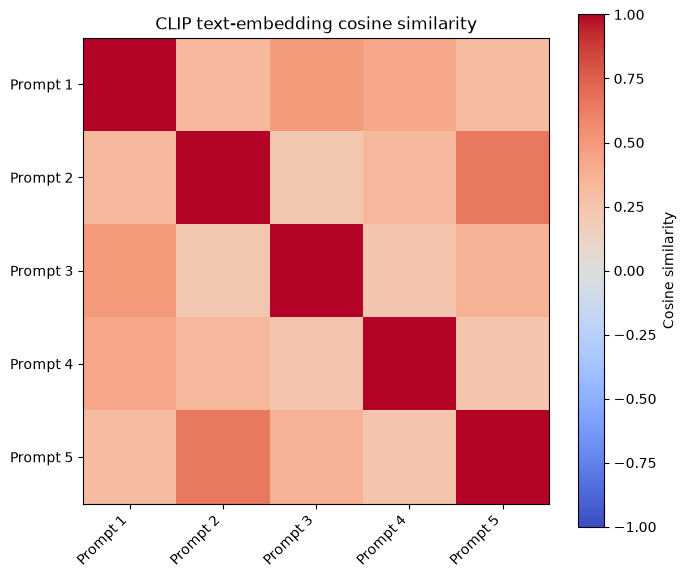

In [6]:
attention_mask = tokens.attention_mask.to(encoder.device).unsqueeze(-1)
pooled = (embeddings * attention_mask).sum(dim=1) / attention_mask.sum(dim=1).clamp(min=1)
normalized = F.normalize(pooled, p=2, dim=1)
similarity = (normalized @ normalized.T).cpu().numpy()

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(similarity, vmin=-1, vmax=1, cmap="coolwarm")
labels = [f"Prompt {index}" for index in range(1, 6)]
ax.set_xticks(range(5), labels, rotation=45, ha="right")
ax.set_yticks(range(5), labels)
ax.set_title("CLIP text-embedding cosine similarity")
fig.colorbar(image, ax=ax, label="Cosine similarity")
fig.tight_layout()
fig.savefig(output_dir / "cosine_similarity.png", dpi=160, bbox_inches="tight")
plt.show()

## Baseline result

The pipeline successfully converts five text prompts into finite CLIP hidden-state tensors with shape `(5, 77, 768)`. The full deterministic prompt manifest contains 4,785 image–caption pairs and is reused by later experiments.